In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random
from itertools import cycle

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from networkx import number_weakly_connected_components
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Simulators.NoiseLevel import NoiseLevel
from halcyon.Simulators.SimulationResult import SimulationResult

from halcyon.Models.PhoenixModels import PhoenixAddAndProdLayers
from halcyon.Models.BaseLineModels import AlwaysDerivativeZero
from halcyon.Models.MechanisticModel import PyTorchODE
from halcyon.Models.HybridModel import HybridModel

from halcyon.ModelRunner import ModelRunner, run_training_job
from halcyon.Losses import MSELossPlusMachineLearningL2
from halcyon.TidyDfResults import TidyDfResults

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

Check if MLFlow connects correctly

In [2]:
import os
print(os.getenv("MLFLOW_TRACKING_URI"))

https://mlflow.cropresilience.org


In [6]:
print(mlflow.get_tracking_uri())
[f"{experiment.name=}" for experiment in mlflow.search_experiments()]

https://mlflow.cropresilience.org


["experiment.name='Halcyon sandbox experiment'",
 "experiment.name='exp'",
 "experiment.name='asdf'",
 "experiment.name='Default'"]

Create experiment

In [7]:
mlflow.set_experiment("Halcyon sandbox experiment")
mlflow.set_experiment_tag("Tool name", "HALCYON") 

# Input data

## Simulating

In [ ]:
# nr_genes_list = [32, 64, 128]
nr_genes_list = [100]
# nr_modules_list = [16, 5, 10]
nr_modules_list = [5]
sparsity_list = [0.1]
out_path = Path("../data/hybrid_model_with_noise") 

keep_self_interactions = False
sim_outputs: list[SimulationResult] = []
for nr_genes in nr_genes_list: 
    for nr_modules in nr_modules_list: 
        for sparsity in sparsity_list: 
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = out_path / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_output = gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
                keep_self_interactions=keep_self_interactions,
                noise_level=NoiseLevel.ALLNOISE,
            )
            sim_output.save_to_pkl(generated_data_path / "simulation_result.pkl")
            
            with mlflow.start_run(run_name=f"dataset_genes{nr_genes}_sparsity{sparsity}_nr_modules{nr_modules}_noise{NoiseLevel.ALLNOISE.name}"):
                mlflow.set_tag("run_type", "dataset")
                mlflow.log_params({
                    "nr_genes": nr_genes,
                    "sparsity": sparsity,
                    "num_modules": nr_modules,
                    "noise_level": NoiseLevel.ALLNOISE.name,
                })

                mlflow.log_artifacts(generated_data_path, artifact_path="dataset")




2026-02-11 13:40:28,230 - INFO - Generating network
2026-02-11 13:40:33,105 - INFO - Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Removing autoregulatory interactions from my_network
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: ~(Node_17*Node_5*Node_2) + ~(Node_28*Node_19*Node_4) + ~(Node_29*Node_13~Node_24)
my_network: Node_1: ~(Node_15*Node_71~Node_20~Node_50) + ~(Node_8*Node_0) + (Node_31) + ~(Node_11)
my_network: Node_2: (Node_30) + (Node_12~Node_1) + (Node_37) + (Node_3*Node_23~Node_35) + ~(Node_7) + (Node_17) + ~(Node_6)
my_network: Node_3: (Node_30*Node_7~Node_6~Node_17) + ~(Node_23*Node_37*Node_2~Node_35) + ~(Node_12*Node_53*Node_43)
my_network: Node_4: (Node_28*Node_5~Node_24) + ~(Node_1*Node_19~Node_0~Node_9)
my_network: Node_5: ~(Node_19*Node_57*Node_29~Node_13) + (Node_4*Node_0) + ~(Node_24)
my_network: Node_6: (Node_3*Node_61*Node_37) + (No

TypeError: Object of type PosixPath is not JSON serializable

## Downloading data from MLFlow

In [ ]:
# 100 genes, sparsity 0.1, 5 modules and all noise run ID
run_id_to_use = "2c38f64e4aa5477fa3b3b17033da0d3d"  
ml_flow_download_path = mlflow.artifacts.download_artifacts(run_id=run_id_to_use, artifact_path="dataset")


2026-02-11 13:45:29,056 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-11 13:45:29,067 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-11 13:45:29,082 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-11 13:45:29,089 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-11 13:45:29,100 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-11 13:45:29,112 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-11 13:45:29,130 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-02-11 13:45:29,145 - WARNING - Connection p

TypeError: halcyon.Simulators.SimulationResult.SimulationResult() argument after ** must be a mapping, not SimulationResult

In [19]:

sim_output = SimulationResult.load_from_pkl(Path(ml_flow_download_path) / "simulation_result.pkl")

In [20]:
sim_output.data_path

PosixPath('/tmp/tmpau21cj8l/dataset')

## Further preprocessing

1


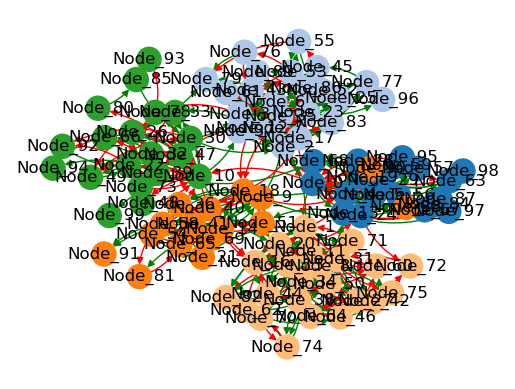

In [21]:
# Do clustering
sim_output.network.do_clustering()

print(number_weakly_connected_components(sim_output.network._graph))

sim_output.network.plot()
plt.show()

In [8]:
for i, module in enumerate(sim_output.network._clustering):
    if 'Node_93' in module:
        print('Module:', i)
        print('Size:', len(module))
        genes_to_select = list(sim_output.network._clustering[i])
        break
genes_to_select

Module: 4
Size: 19


['Node_49',
 'Node_47',
 'Node_66',
 'Node_93',
 'Node_33',
 'Node_73',
 'Node_39',
 'Node_85',
 'Node_99',
 'Node_22',
 'Node_48',
 'Node_92',
 'Node_94',
 'Node_30',
 'Node_10',
 'Node_78',
 'Node_32',
 'Node_26',
 'Node_80']

So select module 4 now for funsies

## Create dataset for training later on

In [22]:
# From sim output to datasets
single_ko_dataset, double_ko_dataset, time_scaling_factor = sim_output.create_datasets()

In [ ]:
with mlflow.start_run(run_name='Generate datasets'):
    single_ko_dataset_path = out_path / "single_ko_dataset.pt"
    double_ko_dataset_path = out_path / "double_ko_dataset.pt"
    torch.save(single_ko_dataset, single_ko_dataset_path)
    torch.save(double_ko_dataset, double_ko_dataset_path)
    mlflow.log_artifact(single_ko_dataset_path)
    mlflow.log_artifact(double_ko_dataset_path)
    mlflow.log_param('time_scaling_factor', time_scaling_factor)

# single_ko_dataset.genes

🏃 View run Generate datasets at: https://mlflow.cropresilience.org/#/experiments/3/runs/b3e6ed1a555046cfa33865e3b61bad20
🧪 View experiment at: https://mlflow.cropresilience.org/#/experiments/3


['Node_0',
 'Node_1',
 'Node_2',
 'Node_3',
 'Node_4',
 'Node_5',
 'Node_6',
 'Node_7',
 'Node_8',
 'Node_9',
 'Node_10',
 'Node_11',
 'Node_12',
 'Node_13',
 'Node_14',
 'Node_15',
 'Node_16',
 'Node_17',
 'Node_18',
 'Node_19',
 'Node_20',
 'Node_21',
 'Node_22',
 'Node_23',
 'Node_24',
 'Node_25',
 'Node_26',
 'Node_27',
 'Node_28',
 'Node_29',
 'Node_30',
 'Node_31',
 'Node_32',
 'Node_33',
 'Node_34',
 'Node_35',
 'Node_36',
 'Node_37',
 'Node_38',
 'Node_39',
 'Node_40',
 'Node_41',
 'Node_42',
 'Node_43',
 'Node_44',
 'Node_45',
 'Node_46',
 'Node_47',
 'Node_48',
 'Node_49',
 'Node_50',
 'Node_51',
 'Node_52',
 'Node_53',
 'Node_54',
 'Node_55',
 'Node_56',
 'Node_57',
 'Node_58',
 'Node_59',
 'Node_60',
 'Node_61',
 'Node_62',
 'Node_63',
 'Node_64',
 'Node_65',
 'Node_66',
 'Node_67',
 'Node_68',
 'Node_69',
 'Node_70',
 'Node_71',
 'Node_72',
 'Node_73',
 'Node_74',
 'Node_75',
 'Node_76',
 'Node_77',
 'Node_78',
 'Node_79',
 'Node_80',
 'Node_81',
 'Node_82',
 'Node_83',
 '

In [ ]:
# Now load the datasets
# Get the artifact URI from the run (can be current run or a past run)
run_id = "Generate datasets"
artifact_path = "datasets/dataset.pt"
artifact_uri = mlflow.get_artifact_uri(artifact_path)  # this gives full URI

# Load the dataset
dataset = torch.load(artifact_uri)

In [ ]:
time_scaling_factor

# Trainers (with different models) creation

In [10]:
train_jobs : list[ModelRunner] = []
device = cycle(['cuda:0', 'cuda:1'])

## Mech model

In [11]:
# Generate MM from this
mm = PyTorchODE.from_sbml(sim_output.data_path / 'my_network.xml',
                           condition_names=[], from_gnw=True, device=next(device))
# Select only genes from specific module and set timescaler
mm.select_genes(genes_to_select, 
                goldstandard_signed_file_for_expression_substitution = sim_output.data_path / f'{network_name}_goldstandard_signed.tsv')
mm.set_timescaler(time_scaling_factor)

print(mm.modelled_gene_labels)

2026-02-10 16:49:05,223 - INFO - Loading SBML model from: /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_with_noise/genes_100_modules_5_sparsity_0.1/my_network.xml


['Node_49', 'Node_47', 'Node_66', 'Node_93', 'Node_33', 'Node_73', 'Node_39', 'Node_85', 'Node_99', 'Node_22', 'Node_48', 'Node_92', 'Node_94', 'Node_30', 'Node_10', 'Node_78', 'Node_32', 'Node_26', 'Node_80']


In [12]:
# Creating MM trainer even though it cannot be trained
mm_trainer = ModelRunner(
    mm,
    save_dir = sim_output.data_path,
    nr_epochs=1,
    batch_size=32,
)

train_jobs.append(mm_trainer)
# mm_trainer.save(mm_trainer.save_path)

## ML and Hybrid model

In [13]:
# for hidden_size in [2, 5, 10]:
#     for do_only_pos in [True, False]:

for hidden_size in [20, 50]:
    for do_only_pos in [True]:        
        ml_model = PhoenixAddAndProdLayers(
                    modelled_gene_labels=single_ko_dataset.genes,
                    hidden_size=hidden_size,
                    condition_names=single_ko_dataset.all_environments,
                    synthesis_only_positive=do_only_pos,
                    device=next(device)
            )

        # Create hybrid model with MM and with add and prod
        hybrid_model = HybridModel(deepcopy(mm), deepcopy(ml_model), device=next(device))
        for model in [ml_model, hybrid_model]:
            # my_loss = MSELossPlusMachineLearningL2(lambda_param=0.5)
            model_runner = ModelRunner(
                model = model,
                save_dir = sim_output.data_path,
                batch_size=32,
                nr_epochs=5,
                optimizer_kwargs = {'lr': 0.1}
            )
            train_jobs.append(model_runner)

## Baseline model (always derivative of 0)

In [14]:
baseline_model = AlwaysDerivativeZero(
    modelled_gene_labels=single_ko_dataset.genes,
    condition_names=single_ko_dataset.all_environments
    )

baseline_trainer = ModelRunner(
    baseline_model,
    save_dir = sim_output.data_path,
    batch_size=32,
    nr_epochs=0,
)
train_jobs.append(baseline_trainer)

2026-02-10 16:50:16,354 - INFO - Using GPU: Tesla T4 (compute capability 7.5)


In [15]:
for job in train_jobs:
    print(job)
    print()

Modelrunner (Model=PyTorchODE with hyperparams: [],
 optimizer=Adam,
 optimizer_kwargs={},
 nr_epochs=1,
 batch_size=32
)

Modelrunner (Model=PhoenixAddAndProdLayers with hyperparams: ['device=cuda:1', 'hidden_size=20', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=5,
 batch_size=32
)

Modelrunner (Model=HybridModel with hyperparams: ['device=cuda:0', 'hidden_size=20', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=5,
 batch_size=32
)

Modelrunner (Model=PhoenixAddAndProdLayers with hyperparams: ['device=cuda:1', 'hidden_size=50', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=5,
 batch_size=32
)

Modelrunner (Model=HybridModel with hyperparams: ['device=cuda:0', 'hidden_size=50', 'synthesis_only_positive=True'],
 optimizer=Adam,
 optimizer_kwargs={'lr': 0.1},
 nr_epochs=5,
 batch_size=32
)

Modelrunner (Model=AlwaysDerivativeZero with hyperparams: [],

In [ ]:
train_jobs[1].nr_epochs = 2
train_jobs[1].train_and_predict_for_mlflow(dataset=single_ko_dataset)

In [ ]:

train_jobs[1].train(dataset=single_ko_dataset)
train_jobs[1].save(train_jobs[1].save_path)

In [ ]:
train_jobs[1].predict(dataset=double_ko_dataset)

# Do training

In [ ]:
mp.set_start_method("spawn", force=True)
with mp.Pool(processes=4) as pool:
    pool.map(run_training_job, train_jobs)

## Load models

In [ ]:
loaded_train_jobs = []
for train_job in train_jobs:
    if train_job.load_if_exists():
        loaded_train_jobs.append(train_job)

loaded_train_jobs

## Do predictions

In [ ]:
# Just make a small subset for testing code
dummy_set = double_ko_dataset.return_subset_copy(size=2)

In [ ]:
len(dummy_set)

In [ ]:
tidy_df = TidyDfResults.from_model_runners_and_datasets(model_runner_list=loaded_train_jobs, dataset_list=[double_ko_dataset])

In [ ]:
tidy_df.df.shape

In [ ]:
tidy_df.to_csv(out_path / "tidy_df_predictions.csv")

## Single KOs

In [ ]:
tidy_df.df.head()

In [ ]:
tidy_df.to_csv(out_path / "tidy_df_single_ko_predictions.csv")

In [ ]:
# example_genes = ['Node_99', 'Node_85', 'Node_48', 'Node_66', 'Node_12']

example_genes = ['Node_0', 'Node_1', 'Node_2']

In [ ]:
tidy_df.df = tidy_df.df[(tidy_df.df['gene'].isin(example_genes))]

In [ ]:
def quick_rename_of_cols(model_name):
    return model_name.replace('_synthesis_only_positive_True_lr_0.1', '').replace('_hidden_size_', '_h_')

In [ ]:
tidy_df.df.model = tidy_df.df.model.apply(quick_rename_of_cols)

In [ ]:
tidy_df.plot_model_plots()

In [ ]:
tidy_df.per_gene_mse_heatmap(robust=True,cmap='plasma')

In [ ]:
tidy_df = TidyDfResults.from_csv(out_path / "tidy_df_single_ko_predictions.csv")

In [ ]:
fig_dir = out_path / 'figures'
fig_dir

In [ ]:
tidy_df.plot_r2()

In [ ]:
tidy_df.plot_mse_per_gene();plt.tight_layout();plt.savefig(fig_dir / 'mse_plot.eps')

In [ ]:
tidy_df.plot_scatterplot()

## Double KOs

In [ ]:
dataset_getter = lambda trainer: trainer.double_ko_dataset
conditions_to_map = tidy_df_creator.get_double_ko_combinations()
len(conditions_to_map)

Bit of debugging / development code

In [ ]:
tidy_df_creator.trainer_list = [tidy_df_creator.trainer_list[5]]

In [ ]:
conditions_to_map = [('Node_10', 'Node_47'), ('Node_0', 'Node_1'), ('Node_0', 'Node_10')][2:]
conditions_to_map

In [ ]:
tidy_df_double_ko = tidy_df_creator.predict_tidy_dataframe_for_all_models_specific_kos(
    conditions_to_map, dataset_getter
)


In [ ]:

tidy_df_double_ko.to_csv(out_path / "tidy_df_double_ko_predictions.csv")
# tidy_df.to_parquet(out_path / "tidy_df_single_ko_predictions.parquet")

In [ ]:
tidy_df_double_ko = TidyDfResults.from_csv(out_path / "tidy_df_double_ko_predictions.csv")

In [ ]:
tidy_df_double_ko.df.model = tidy_df_double_ko.df.model.apply(quick_rename_of_cols)

In [ ]:
tidy_df_double_ko.per_gene_mse_heatmap(robust=False,cmap='plasma')


In [ ]:
plt.savefig(fig_dir / 'double_ko_mse_heatmap.eps', bbox_inches='tight')

In [ ]:
tidy_df_double_ko.df.head()

In [ ]:
double_ko_genes_to_select = [
    "Node_33",
    "Node_26",
    "Node_32",
    "Node_10",
    "Node_30",
    "Node_22",
    "Node_80",
    "Node_99",
    "Node_92",
    "Node_93",
    "Node_17",
    "Node_0"
]
tidy_df_double_ko.df = tidy_df_double_ko.df[(tidy_df_double_ko.df['gene'].isin(double_ko_genes_to_select)) & (tidy_df_double_ko.df['condition'] == 'KO: Node_10, Node_47')]
tidy_df_double_ko.df.head()

In [ ]:
tidy_df_double_ko.plot_model_plots()

In [ ]:
g = tidy_df_double_ko.plot_mse_per_gene(split_by_condition_in_mm=True); 
g.figure.suptitle("Per-gene MSE for Double knockouts")
plt.tight_layout()
# plt.show()
plt.savefig(fig_dir / 'per_gene_mse_double_ko_split_by_ko_in_mm.svg')

In [ ]:
tidy_df_double_ko.plot_r2()
# plt.show()
plt.savefig(fig_dir / 'r2_plot_double_ko_split_by_ko_in_mm.eps')

In [ ]:
tidy_df_double_ko.kde_plot(subsample_first=True);plt.show()

In [ ]:
tidy_df_double_ko.plot_scatterplot();plt.show()

## Loss

In [ ]:
for result in tidy_df_creator.trainer_list:
    # print(result.loss_history)
    plt.plot(result.loss_history, label=result.get_save_file_name())
plt.legend()
plt.yscale('log')
# plt.xscale('log')
plt.tight_layout()
plt.show()
# plt.savefig(fig_dir / 'loss_history_plot.svg')